# Bivariate Analysis

Bivariate analysis means studying the relationship between two variables to understand how they are associated with each other.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the Online Retail dataset
df = pd.read_csv("data.csv", encoding="cp1252")

# Convert numerical columns
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")

# Convert invoice date
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"], errors="coerce"
)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## Numerical vs Numerical
This analysis studies the relationship between two numerical variables.
In our dataset, we will compare Quantity and UnitPrice.
###  Scatter plot
A scatter plot shows the relationship between two numerical variables. Each point represents a transaction line.

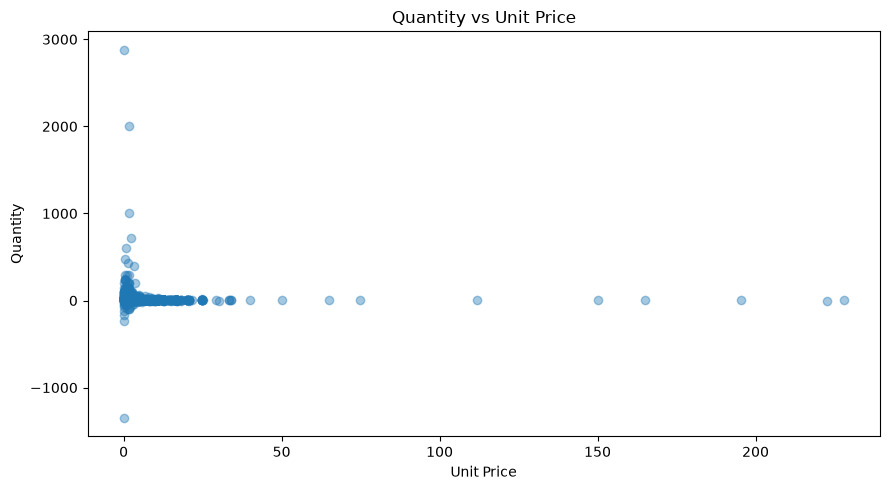

In [6]:
# Use a sample to make the plot easier to read
plot_df = df[
    ["Quantity", "UnitPrice"]
].dropna().sample(
    n=min(5000, len(df.dropna(subset=["Quantity", "UnitPrice"]))),
    random_state=42
)

plt.figure(figsize=(9, 5))

plt.scatter(
    plot_df["UnitPrice"],
    plot_df["Quantity"],
    alpha=0.4
)

plt.title("Quantity vs Unit Price")
plt.xlabel("Unit Price")
plt.ylabel("Quantity")
plt.tight_layout()
plt.show()

### Correlation
Correlation measures the strength and direction of a linear relationship between numerical variables.

In [7]:
correlation = df[
    ["Quantity", "UnitPrice"]
].corr(method="pearson")

print(correlation)

           Quantity  UnitPrice
Quantity   1.000000  -0.001235
UnitPrice -0.001235   1.000000


## Numerical vs Categorical
This analysis compares a numerical variable across different categories.
For our dataset, we will compare Quantity across countries.
### Box plot
A box plot compares the distribution of numerical values across categories.
To keep the plot readable, we will use the five countries with the most transaction records.

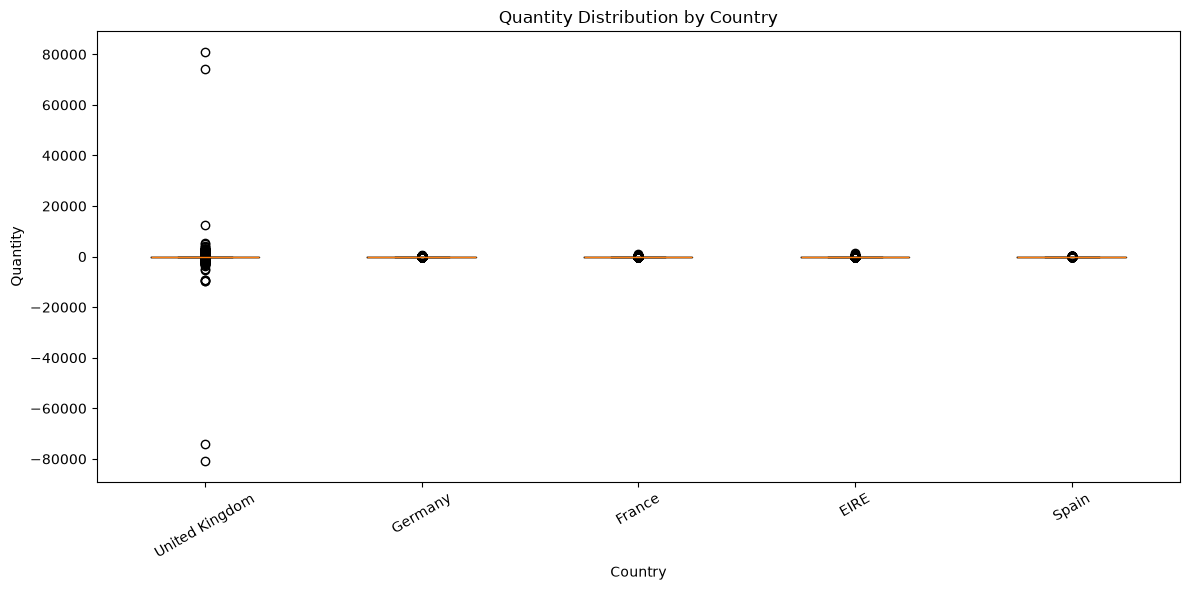

In [8]:
top_countries = df["Country"].value_counts().head(5).index

box_df = df[df["Country"].isin(top_countries)].copy()

plt.figure(figsize=(12, 6))

box_data = [
    box_df.loc[box_df["Country"] == country, "Quantity"].dropna()
    for country in top_countries
]

plt.boxplot(box_data, tick_labels=top_countries)

plt.title("Quantity Distribution by Country")
plt.xlabel("Country")
plt.ylabel("Quantity")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Violin plot
A violin plot shows the distribution and approximate density of a numerical variable within each category.

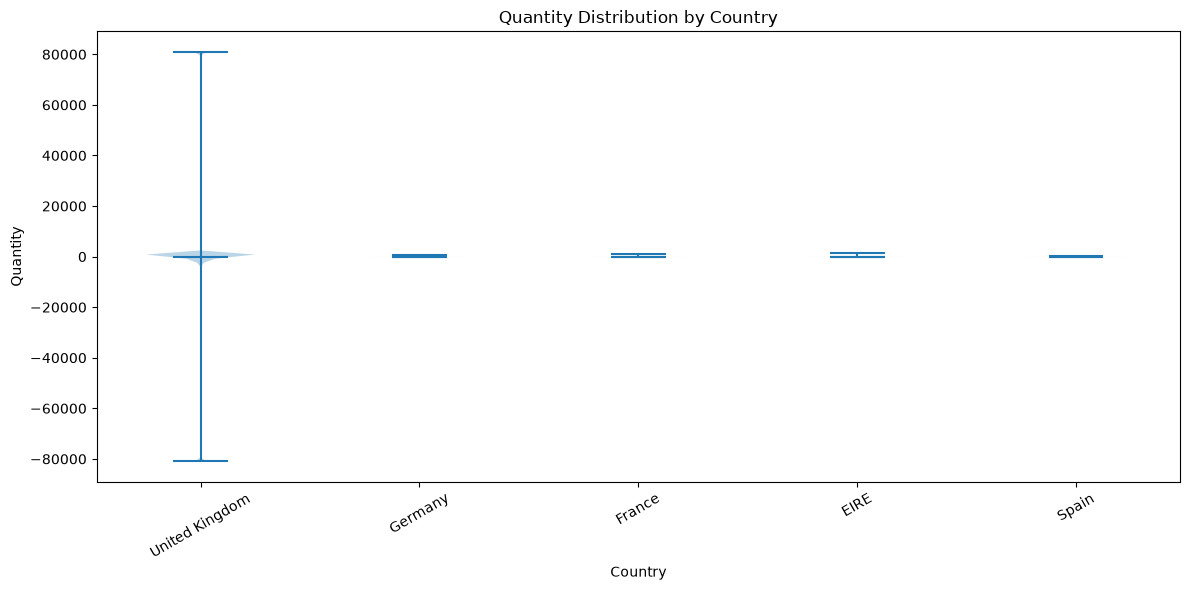

In [9]:
plt.figure(figsize=(12, 6))

violin_data = [
    box_df.loc[box_df["Country"] == country, "Quantity"].dropna()
    for country in top_countries
]

plt.violinplot(
    violin_data,
    showmedians=True,
    showextrema=True
)

plt.title("Quantity Distribution by Country")
plt.xlabel("Country")
plt.ylabel("Quantity")
plt.xticks(
    range(1, len(top_countries) + 1),
    top_countries,
    rotation=30
)

plt.tight_layout()
plt.show()

## Group statistics
We can also compare countries using numerical summaries.

In [10]:
country_quantity_summary = (
    df.groupby("Country")["Quantity"]
      .agg(["count", "mean", "median", "min", "max"])
      .sort_values("count", ascending=False)
      .head(10)
)

display(country_quantity_summary)

,count,mean,median,min,max
Country,,,,,
United Kingdom,495478,8.605486,3.0,-80995,80995
Germany,9495,12.369458,10.0,-288,600
France,8557,12.911067,10.0,-250,912
EIRE,8196,17.403245,10.0,-288,1440
Spain,2533,10.589814,6.0,-288,360
Netherlands,2371,84.406580,72.0,-480,2400
Belgium,2069,11.189947,10.0,-12,272
Switzerland,2002,15.147353,12.0,-120,288
Portugal,1519,10.651745,8.0,-12,120


## Categorical vs Categorical
This analysis examines how two categorical variables are related.
For the Online Retail dataset, we can compare Country with a derived TransactionType category. Invoice numbers beginning with C are commonly used to indicate cancellations in this dataset, but verify the dataset documentation and invoice records before relying on that classification.
### Cross-tabulation
A cross-tabulation counts combinations of two categorical variables.

In [12]:
# Use the top five countries
top_countries = analysis_df["Country"].value_counts().head(5).index

subset = analysis_df[
    analysis_df["Country"].isin(top_countries)
]

cross_tab = pd.crosstab(
    subset["Country"],
    subset["TransactionType"]
)

display(cross_tab)

TransactionType,Cancellation-like,Other
Country,,
EIRE,302,7894
France,149,8408
Germany,453,9042
Spain,48,2485
United Kingdom,7856,487622


### Percentage cross-tabulation
To compare the share of each transaction type within each country, use row percentages.

In [13]:
cross_tab_percentage = pd.crosstab(
    subset["Country"],
    subset["TransactionType"],
    normalize="index"
) * 100

display(cross_tab_percentage.round(2))

TransactionType,Cancellation-like,Other
Country,,
EIRE,3.68,96.32
France,1.74,98.26
Germany,4.77,95.23
Spain,1.89,98.11
United Kingdom,1.59,98.41


## Grouped bar chart

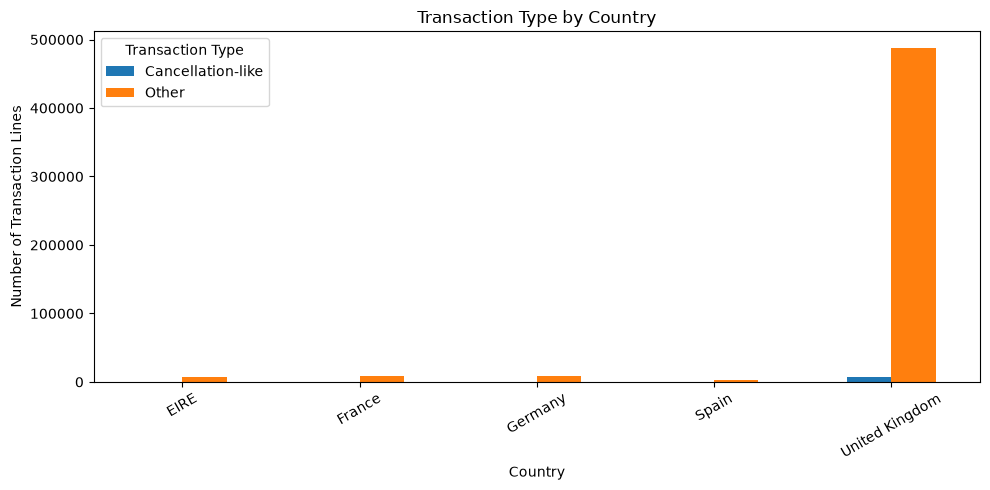

In [14]:
cross_tab.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Transaction Type by Country")
plt.xlabel("Country")
plt.ylabel("Number of Transaction Lines")
plt.xticks(rotation=30)
plt.legend(title="Transaction Type")
plt.tight_layout()
plt.show()